# Stock movement report

Two questions about tomorrow, each answered using only information available at today's close, and each compared with simple rules:

- **Part 1, direction (sections 1–7):** will the stock close higher tomorrow?
- **Part 2, move size (sections 8–12):** will tomorrow's move, up or down, be bigger than usual?

This notebook is a **template**. `python run.py NVDA` fills in the settings below and saves the finished report as `reports/NVDA.ipynb`. To run it by hand, change `TICKER` in the next cell and run all cells.

**Why direction, not price:** tomorrow's price is almost always close to today's, so a "predicted vs. actual price" chart looks impressive even for a model that has learned nothing. Up-or-down is a much harder test to fake.

**What "honest" means here:**
1. **No peeking at the future.** Every feature uses only data up to today's close, and the model is always tested on years it never saw during training.
2. **Real baselines.** Beating a coin flip is easy because stocks rise more often than they fall. The bar is the rule "always predict up."
3. **Noise check.** Every accuracy comes with a range showing how much could be luck.
4. **Money check.** A backtest with trading costs, compared against simply buying and holding, plus a luck check.
5. **Pipeline checks.** The same code must find nothing in pure noise, and must find a pattern that is planted on purpose.

In [1]:
# Settings (run.py replaces these)
TICKER = "SPY"
START = "2005-01-01"
# First year to predict. None = automatic: the first year with about 4 years of history before it
FIRST_TEST_YEAR = None
# Cost per buy or sell in the backtest: 0.001 = 0.1%
COST = 0.001

In [2]:
# Parameters
TICKER = "GOOGL"
START = "2005-01-01"
FIRST_TEST_YEAR = None
COST = 0.001


In [3]:
import sys
from pathlib import Path

# Find the project folder, whether this runs from the project, notebooks/ or reports/
ROOT = Path.cwd()
if ROOT.name in ("notebooks", "reports"):
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from cycler import cycler
from IPython.display import Markdown, display

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
# Same colors in every report: blue, orange, aqua, yellow
plt.rcParams["axes.prop_cycle"] = cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])

from src.data import load_prices, make_random_walk, make_planted_pattern, make_volatility_clusters
from src.features import (FEATURES, ALL_FEATURES, VOL_FEATURES, TYPICAL_WINDOW,
                          build_dataset, build_vol_dataset)
from src.evaluate import (get_models, first_test_year, walk_forward, baseline_predictions,
                          vol_baseline_predictions, accuracy_table, accuracy_by_year,
                          backtest_table, luck_check, paired_p_value, hold_for_week)
from src.report import summarize, summarize_vol, half_on_big, save_summary

display(Markdown(f"# {TICKER}: predicting tomorrow's direction and move size"))

# GOOGL: predicting tomorrow's direction and move size

# Part 1: direction

## 1. Data

Daily prices, adjusted for dividends and splits. The first run downloads them; later runs load the saved copy in `data/`. `python run.py TICKER --refresh` pulls the latest days.

If the data was downloaded while the US market was still open, today's row is left out automatically: its "close" isn't final yet.

5,482 trading days, 2005-01-03 to 2026-10-16


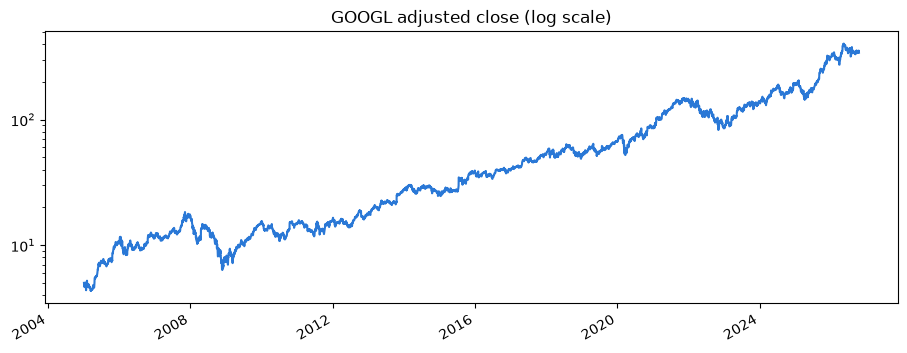

In [4]:
prices = load_prices(TICKER, START)
print(f"{len(prices):,} trading days, {prices.index[0].date()} to {prices.index[-1].date()}")

ax = prices["Close"].plot(logy=True, title=f"{TICKER} adjusted close (log scale)")
ax.set_xlabel("")
plt.show()

In [5]:
daily_ret = prices["Close"].pct_change().dropna()
growth = prices["Close"].iloc[-1] / prices["Close"].iloc[0]
print(f"Share of up days: {(daily_ret > 0).mean():.1%}")

display(Markdown(
    f"**A note on hindsight.** \\$1 in {TICKER} on {prices.index[0].date()} grew to "
    f"\\${growth:,.2f} by {prices.index[-1].date()}. If {TICKER} was chosen because it is a "
    f"well-known success today, buy-and-hold looks good partly in hindsight: nobody in "
    f"{prices.index[0].year} knew how it would turn out. This affects the buy-and-hold "
    f"comparison, not the model tests: the models still had to predict each day using only the past."
))

Share of up days: 52.5%


**A note on hindsight.** \$1 in GOOGL on 2005-01-03 grew to \$67.78 by 2026-10-16. If GOOGL was chosen because it is a well-known success today, buy-and-hold looks good partly in hindsight: nobody in 2005 knew how it would turn out. This affects the buy-and-hold comparison, not the model tests: the models still had to predict each day using only the past.

The share of up days is the accuracy of "always predict up." Any model has to beat it, not 50%, to show it has learned something.

## 2. Features and label

Eight features are calculated. The models use five of them, one per idea:

| Feature | Meaning | Used by the models? |
|---|---|---|
| `ret_1d` | Return over the last day | Yes |
| `ret_5d` | Return over the last 5 days (one week) | Yes |
| `dist_ma50` | How far today's price is above or below its 50-day average (longer trend) | Yes |
| `vol_20d` | How jumpy daily returns were over the last 20 days (risk) | Yes |
| `volume_ratio` | Today's volume compared with its 20-day average (activity) | Yes |
| `ret_10d`, `ret_20d` | Return over the last 10 and 20 days | No: overlap with the kept features |
| `dist_ma10` | Distance from the 10-day average | No: nearly a copy of `ret_5d` |

The **label** (`target`) is 1 if tomorrow's close is higher than today's, else 0. `next_ret` is tomorrow's return, kept for the backtest.

In [6]:
data = build_dataset(prices)
if FIRST_TEST_YEAR is None:
    FIRST_TEST_YEAR = first_test_year(data)
print(f"First test year: {FIRST_TEST_YEAR}")
data.head()

First test year: 2010


,ret_1d,ret_5d,ret_10d,ret_20d,dist_ma10,dist_ma50,vol_20d,volume_ratio,next_ret,target
Date,,,,,,,,,,
2005-03-15,0.0207,-0.0356,-0.0400,-0.0745,-0.0212,-0.0671,0.0157,-0.1073,-0.0169,0
2005-03-16,-0.0169,-0.0317,-0.0517,-0.1005,-0.0326,-0.0802,0.0155,-0.3384,0.0210,1
2005-03-17,0.0210,-0.0038,-0.0413,-0.0964,-0.0081,-0.0594,0.0159,-0.2002,0.0042,1
2005-03-18,0.0042,0.0126,-0.0315,-0.0902,-0.0007,-0.0541,0.0160,-0.3023,0.0047,1
2005-03-21,0.0047,0.0337,-0.0420,-0.0862,0.0084,-0.0490,0.0161,-0.2599,-0.0126,0


### Why only five? Overlapping features

When two features measure nearly the same thing, a model can split weight between them or give them opposite weights that cancel out, so you can no longer read what it learned. Correlation runs from -1 to 1; values near ±1 mean two features move together.

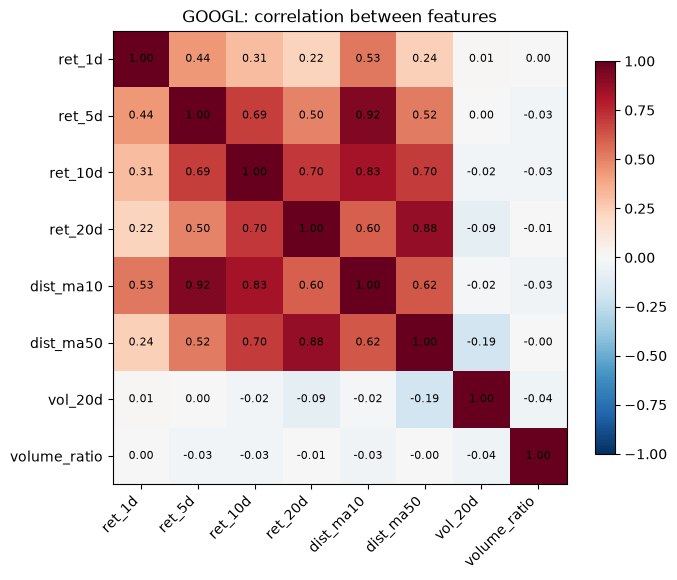

In [7]:
corr = data[ALL_FEATURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ALL_FEATURES)), ALL_FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(ALL_FEATURES)), ALL_FEATURES)
for i in range(len(ALL_FEATURES)):
    for j in range(len(ALL_FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title(f"{TICKER}: correlation between features")
plt.tight_layout()
plt.show()

How strongly does each feature relate to tomorrow's return? Expect numbers close to zero, which is the first hint of how hard this is.

In [8]:
data[ALL_FEATURES].corrwith(data["next_ret"]).sort_values().to_frame("correlation with next-day return")

,correlation with next-day return
dist_ma10,-0.0279
ret_1d,-0.0254
ret_5d,-0.0179
ret_10d,-0.0145
vol_20d,-0.0108
dist_ma50,-0.0092
ret_20d,-0.0058
volume_ratio,0.0135


## 3. Walk-forward testing

A random train/test split would let the model train on 2020 and then "predict" 2015, which is peeking at the future. Instead:

- Train on all years before the first test year, predict every day of that year.
- Add that year to the training data, predict the next year.
- ...and so on up to today.

Every prediction is made by a model that only saw earlier years, just like it would be used in real life.

In [9]:
model_preds = {}
for name, model in get_models().items():
    model_preds[name] = walk_forward(model, data, FIRST_TEST_YEAR)
    print(f"{name}: done")

test = data[data.index.year >= FIRST_TEST_YEAR]
baselines = baseline_predictions(test)

all_preds = {name: p["pred"] for name, p in model_preds.items()}
all_preds.update({name: baselines[name] for name in baselines})
print(f"Test period: {test.index[0].date()} to {test.index[-1].date()} ({len(test):,} days)")

Logistic regression: done


Gradient boosting: done
Test period: 2010-01-04 to 2026-10-15 (4,222 days)


## 4. Results: accuracy

How to read this table:
- **range low / range high**: the 95% range. Two methods whose ranges overlap heavily can't really be told apart.
- **predicted up**: if a model says "up" on nearly every day, it has mostly learned "always up," not a real pattern.
- **p-value vs coin flip**: small values mean it beats coin flipping. Notice "Always up" passes this test too, which is why it's a weak test.
- **beats always-up?**: the honest test. True only if the model is better than "always up" by more than noise.

In [10]:
accuracy_table(all_preds, test["target"])

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.5206,0.5055,0.5357,0.9031,0.0039,False
Gradient boosting,0.5173,0.5022,0.5324,0.6094,0.0128,False
Coin flip,0.5085,0.4934,0.5236,0.5040,0.1373,False
Always up,0.5284,0.5134,0.5435,1.0000,0.0001,False
Repeat last move,0.5009,0.4859,0.5160,0.5287,0.4571,False


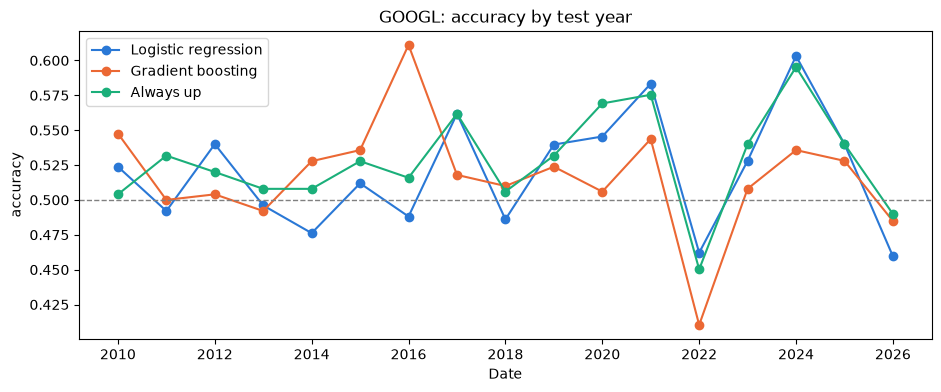

In [11]:
by_year = accuracy_by_year(all_preds, test["target"])
ax = by_year[list(model_preds) + ["Always up"]].plot(marker="o", title=f"{TICKER}: accuracy by test year")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("accuracy")
plt.show()

Questions to ask yourself here: does a model beat "always up" consistently, or only in a few years? Which years are bad, and what happened in markets then?

### Do the three left-out features help?

The same walk-forward test with all eight features. If the left-out features only repeated what the kept ones already say, accuracy should barely change.

In [12]:
rows = {}
for name, model in get_models().items():
    for label, feats in [("5 features", FEATURES), ("all 8 features", ALL_FEATURES)]:
        p = walk_forward(model, data, FIRST_TEST_YEAR, features=feats)
        rows[(name, label)] = {"accuracy": (p["pred"] == test["target"]).mean(),
                               "predicted up": p["pred"].mean()}
pd.DataFrame(rows).T

accuracy  predicted up
Logistic regression 5 features        0.5206        0.9031
                    all 8 features    0.5246        0.8598
Gradient boosting   5 features        0.5173        0.6094
                    all 8 features    0.5201        0.5990

## 5. Backtest: would it have made money?

Strategy: at each close, hold the stock into tomorrow if the model predicts up, otherwise sit in cash. Each buy or sell costs `COST`. Compared against buying once and holding.

In [13]:
positions = {"Buy and hold": pd.Series(1, index=test.index)}
positions.update({name: p["pred"] for name, p in model_preds.items()})

stats, daily_returns = backtest_table(positions, test["next_ret"], cost=COST)
stats

,total return,annual return,annual volatility,Sharpe ratio,max drawdown,days in market,trades
Buy and hold,20.8998,0.2023,0.2787,0.8001,-0.4432,1.0000,1
Logistic regression,5.6098,0.1193,0.2539,0.5704,-0.4366,0.9031,277
Gradient boosting,1.1727,0.0474,0.2241,0.3180,-0.5529,0.6094,1673


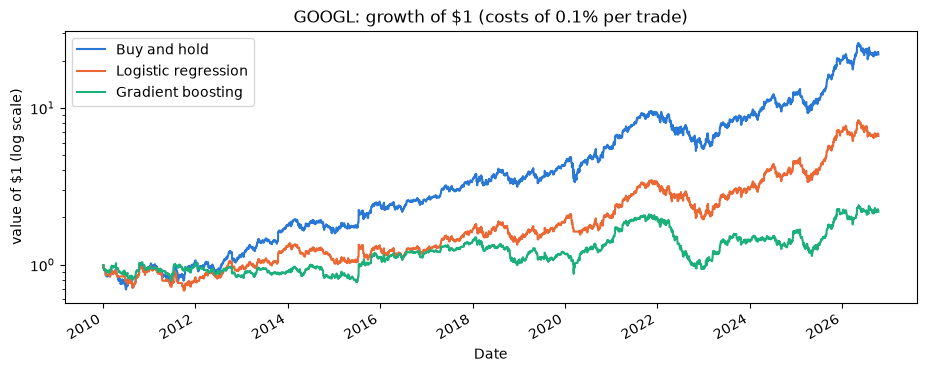

In [14]:
ax = (1 + daily_returns).cumprod().plot(logy=True, title=f"{TICKER}: growth of $1 (costs of {COST:.1%} per trade)")
ax.set_ylabel("value of $1 (log scale)")
plt.show()

Trading costs matter. Here's the same backtest at different cost levels. A strategy that only wins when trading is free isn't a real edge.

In [15]:
rows = {}
for cost in [0, 0.0005, 0.001, 0.002]:
    s, _ = backtest_table(positions, test["next_ret"], cost=cost)
    rows[f"{cost:.2%}"] = s["annual return"]
pd.DataFrame(rows).rename_axis(columns="cost per trade")

cost per trade,0.00%,0.05%,0.10%,0.20%
Buy and hold,0.2024,0.2023,0.2023,0.2022
Logistic regression,0.1380,0.1286,0.1193,0.1009
Gradient boosting,0.1574,0.1010,0.0474,-0.0522


### Is any edge just luck?

A strategy that sits in cash on a few days can beat buy-and-hold just by happening to miss some bad days. To check, keep the same number of cash days but pick them at random, 2,000 times. The random versions trade for free, which is generous to luck, so this is a strict test.

- **share of random >=**: how often a random choice of cash days did at least as well. Around 0.05 or less is hard to explain by luck; much higher means the result is easy to get by chance.
- **Biggest days avoided / missed**: if a handful of extreme days drive the result, it's fragile. One lucky day in a crash can make a strategy look good for a decade.

In [16]:
luck = {}
for name, p in model_preds.items():
    if (p["pred"] == 0).any():
        luck[name] = luck_check(p["pred"], test["next_ret"], cost=COST)
if luck:
    display(pd.DataFrame(luck).T)
else:
    print("Both models stayed in the market every day: nothing to compare with random cash days.")

for name, p in model_preds.items():
    cash_days = test.loc[p["pred"] == 0, "next_ret"].sort_values()
    if len(cash_days) == 0:
        continue
    print(f"\n{name}: {len(cash_days)} days in cash")
    print("  Biggest drops avoided:", ", ".join(f"{d.date()} {r:+.1%}" for d, r in cash_days.head(3).items()))
    print("  Biggest rises missed: ", ", ".join(f"{d.date()} {r:+.1%}" for d, r in cash_days.tail(3)[::-1].items()))

,annual return,random median,share of random >=,cash days
Logistic regression,0.1193,0.1807,0.9990,409.0000
Gradient boosting,0.0474,0.1200,0.9665,1649.0000



Logistic regression: 409 days in cash
  Biggest drops avoided: 2020-03-13 -11.6%, 2012-01-19 -8.4%, 2020-03-11 -8.2%
  Biggest rises missed:  2020-03-12 +9.2%, 2020-04-28 +8.9%, 2020-04-03 +8.3%

Gradient boosting: 1649 days in cash
  Biggest drops avoided: 2020-03-13 -11.6%, 2022-10-25 -9.1%, 2011-04-14 -8.3%
  Biggest rises missed:  2013-10-17 +13.8%, 2024-04-25 +10.2%, 2025-04-08 +9.7%


## 6. Checking the pipeline itself

Two tests on fake prices, run through exactly the same code as the real data. Together they show the "detector" works both ways.

### 6a. Pure noise: the models should find nothing

Fake prices where every day is pure chance. Nothing can be predicted, so the models should land close to "always up." If a model clearly beats it here, the code is leaking future information and the real results can't be trusted.

In [17]:
def check_on_fake_prices(fake_prices):
    fake = build_dataset(fake_prices)
    start_year = first_test_year(fake)
    fake_test = fake[fake.index.year >= start_year]
    preds = {name: walk_forward(m, fake, start_year)["pred"] for name, m in get_models().items()}
    preds["Always up"] = pd.Series(1, index=fake_test.index)
    preds["Repeat last move"] = (fake_test["ret_1d"] > 0).astype(int)
    return accuracy_table(preds, fake_test["target"])

check_on_fake_prices(make_random_walk(n_days=len(prices), start=prices.index[0]))

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.4896,0.4744,0.5047,0.3744,0.9133,False
Gradient boosting,0.4941,0.4790,0.5093,0.4652,0.7804,False
Always up,0.5023,0.4871,0.5174,1.0000,0.3903,False
Repeat last move,0.4970,0.4818,0.5122,0.5025,0.6563,False


### 6b. A planted pattern: the models should find it

Fake prices with a pattern built in on purpose: after an up day, the next day is down 60% of the time, and after a down day, the next day is up 60% of the time. Up and down days are equally common, so "always up" scores about 50%, while a model that learns "bet against yesterday's move" should score about 60%. Both models should show **True** in "beats always-up?".

This is what makes the real-data result meaningful: the same code finds a pattern when one exists, so finding nothing in real prices means there was nothing to find.

In [18]:
check_on_fake_prices(make_planted_pattern(n_days=len(prices), start=prices.index[0]))

,accuracy,range low,range high,predicted up,p-value vs coin flip,beats always-up?
Logistic regression,0.5952,0.5803,0.6101,0.5028,0.0000,True
Gradient boosting,0.5772,0.5622,0.5922,0.5130,0.0000,True
Always up,0.4958,0.4806,0.5110,1.0000,0.7112,False
Repeat last move,0.3953,0.3804,0.4101,0.4958,1.0000,False


## 7. What did logistic regression learn?

Weights from a model fitted on all the data. Features were scaled first, so the sizes are comparable: positive means "this pushes toward predicting up." With five non-overlapping features, each bar can be read on its own. This describes the model; it doesn't prove the patterns are real.

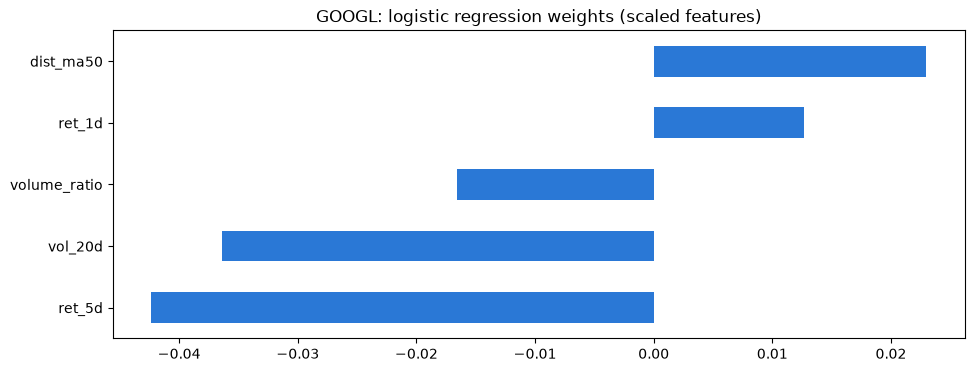

In [19]:
logreg = get_models()["Logistic regression"].fit(data[FEATURES], data["target"])
weights = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
weights.plot.barh(title=f"{TICKER}: logistic regression weights (scaled features)")
plt.show()

# Part 2: big vs. small moves

Direction looks unpredictable. Move size is a different story: markets show **volatility clustering**, where wild days tend to follow wild days and calm days follow calm days. Part 2 asks whether tomorrow will be a big or a small move, up or down, using the same honest tests as Part 1.

## 8. What counts as "big"?

A fixed bar like "moved more than 1%" doesn't work across stocks: a wild stock beats it most days, a calm fund rarely. So:

> **Big = tomorrow's move, up or down, is larger than this stock's typical day over the past year.**

"Typical" is the median size of the daily moves over the previous 250 trading days, calculated from data up to today only. Roughly half of all days are big, and the bar adapts as markets get calmer or wilder.

Share of big days: 49.7%


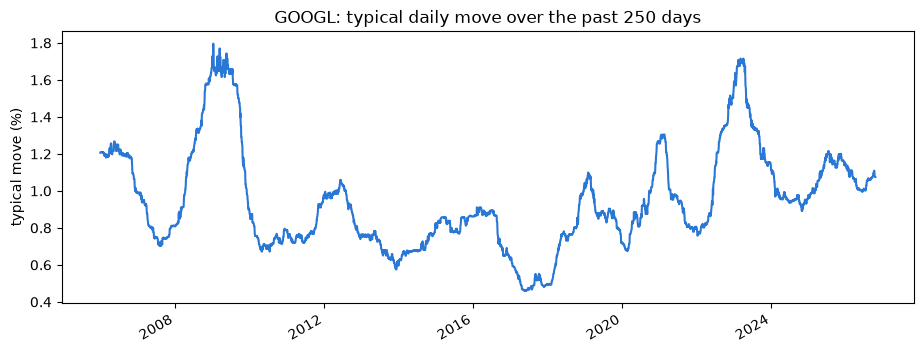

In [20]:
vol_data = build_vol_dataset(prices)
print(f"Share of big days: {vol_data['target'].mean():.1%}")
ax = (vol_data["typical_move"] * 100).plot(title=f"{TICKER}: typical daily move over the past {TYPICAL_WINDOW} days")
ax.set_ylabel("typical move (%)")
ax.set_xlabel("")
plt.show()

The line shows the bar that "big" is measured against. It rises in turbulent years and falls in calm ones.

## 9. Features

Every feature measures the size of recent moves, relative to the stock's typical move (like the label), so a 2% day counts as big for a calm fund but ordinary for a wild stock.

| Feature | Meaning |
|---|---|
| `abs_ret_rel` | Today's move size |
| `vol_5d_rel` | How jumpy the last week was |
| `vol_20d_rel` | How jumpy the last month was |
| `range_rel` | How far the price swung within today, from low to high |
| `volume_ratio` | Today's volume compared with its 20-day average |

Unlike in Part 1, these features should relate clearly to the label. Correlation runs from -1 to 1:

In [21]:
vol_data[VOL_FEATURES].corrwith(vol_data["target"]).sort_values().to_frame("correlation with a big day tomorrow")

,correlation with a big day tomorrow
abs_ret_rel,0.0633
volume_ratio,0.0665
vol_20d_rel,0.1433
vol_5d_rel,0.1467
range_rel,0.1593


## 10. Walk-forward results

The same walk-forward test as Part 1: every prediction comes from models trained only on earlier years.

The baselines, from weakest to strongest:
- **Always small / Always big:** the majority rule. Whichever is right more often is the bar for "better than guessing."
- **Same as today:** if today's move was bigger than usual, predict tomorrow's will be too. Volatility clustering in one line.
- **Recent swing:** if today's high-to-low swing was wider than its median over the past year, predict a big day. Still one line, with no model and no fitting, but it uses a better measure of how wild today was. This is **the real bar**: a model only adds something if it beats this rule.

A rule is a prediction for the same days as the model, and the two agree on most of them. Those days say nothing about which is better, so the comparison uses a **paired test**: only the days where they disagree count.

- **p-value vs recent swing / vs same as today:** the chance that the model would win this many of the disagreement days if it were no better than that rule.
- **beats recent swing?** True if that p-value is below 0.05.

In [22]:
vol_first_year = first_test_year(vol_data)
vol_model_preds = {name: walk_forward(model, vol_data, vol_first_year, features=VOL_FEATURES)
                   for name, model in get_models().items()}
vol_test = vol_data[vol_data.index.year >= vol_first_year]
vol_baselines = vol_baseline_predictions(vol_test)

vol_preds = {name: p["pred"] for name, p in vol_model_preds.items()}
vol_preds.update({name: vol_baselines[name] for name in vol_baselines})
print(f"Test period: {vol_test.index[0].date()} to {vol_test.index[-1].date()} ({len(vol_test):,} days)")
vol_accuracy = accuracy_table(vol_preds, vol_test["target"], baseline="Recent swing")
vol_accuracy.insert(len(vol_accuracy.columns) - 2, "p-value vs same as today",
                    [paired_p_value(p, vol_baselines["Same as today"], vol_test["target"]) for p in vol_preds.values()])
vol_accuracy.rename(columns={"predicted up": "predicted big"})

Test period: 2010-01-04 to 2026-10-15 (4,222 days)


,accuracy,range low,range high,predicted big,p-value vs coin flip,p-value vs same as today,p-value vs recent swing,beats recent swing?
Logistic regression,0.5632,0.5483,0.5782,0.3631,0.0000,0.0000,0.0171,True
Gradient boosting,0.5509,0.5359,0.5659,0.4479,0.0000,0.0000,0.3523,False
Always small,0.5000,0.4849,0.5151,0.0000,0.5061,0.7069,1.0000,False
Always big,0.5000,0.4849,0.5151,1.0000,0.5061,0.7068,1.0000,False
Same as today,0.5057,0.4906,0.5208,0.4998,0.2347,1.0000,1.0000,False
Recent swing,0.5474,0.5324,0.5624,0.4931,0.0000,0.0000,1.0000,False


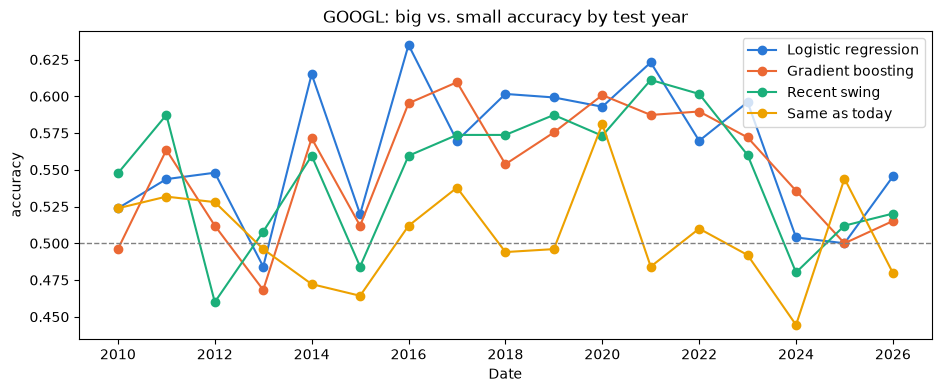

In [23]:
by_year = accuracy_by_year(vol_preds, vol_test["target"])
ax = by_year[list(vol_model_preds) + ["Recent swing", "Same as today"]].plot(marker="o", title=f"{TICKER}: big vs. small accuracy by test year")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("accuracy")
plt.show()

### Where do the models and the rule disagree?

The paired test in numbers: on how many days does each model disagree with the Recent swing rule, and who is right on those days?

In [24]:
rule = vol_baselines["Recent swing"]
target = vol_test["target"]
rows = {}
for name, p in vol_model_preds.items():
    differ = p["pred"] != rule
    rows[name] = {"days they disagree": int(differ.sum()),
                  "share of all days": differ.mean(),
                  "model right": int((differ & (p["pred"] == target)).sum()),
                  "rule right": int((differ & (rule == target)).sum()),
                  "p-value vs recent swing": paired_p_value(p["pred"], rule, target)}
pd.DataFrame(rows).T

,days they disagree,share of all days,model right,rule right,p-value vs recent swing
Logistic regression,971.0000,0.2300,519.0000,452.0000,0.0171
Gradient boosting,1363.0000,0.3228,689.0000,674.0000,0.3523


## 11. Checking the pipeline for move size

The same two kinds of check as Part 1, built for this task.

- **Constant volatility:** fake prices where every day is equally wild. Nothing about tomorrow's move size can be predicted, so every method should land near 50%.
- **Clustered volatility:** fake prices with wild and calm spells planted on purpose (the GARCH model, with settings typical of a stock index). The models should find them and beat both rules.

On the fake prices, the high-to-low swing within a day is mostly random noise around the day's move, so the Recent swing rule is much weaker there than on real prices. The point of this check is the models, not the rule.

In [25]:
def check_vol_on_fake_prices(fake_prices):
    fake = build_vol_dataset(fake_prices)
    start_year = first_test_year(fake)
    fake_test = fake[fake.index.year >= start_year]
    preds = {name: walk_forward(m, fake, start_year, features=VOL_FEATURES)["pred"]
             for name, m in get_models().items()}
    base = vol_baseline_predictions(fake_test)
    preds.update({name: base[name] for name in ["Always small", "Same as today", "Recent swing"]})
    table = accuracy_table(preds, fake_test["target"], baseline="Recent swing")
    table["beats same as today?"] = accuracy_table(preds, fake_test["target"], baseline="Same as today")["beats same as today?"]
    table = table[["accuracy", "range low", "range high", "beats recent swing?", "beats same as today?"]]
    # The "beats" columns are about the models; leave them empty for the rules themselves
    table.loc[list(base.columns.intersection(table.index)), ["beats recent swing?", "beats same as today?"]] = ""
    return table

display(Markdown("**Constant volatility** (should find nothing):"))
display(check_vol_on_fake_prices(make_random_walk(n_days=len(prices), start=prices.index[0])))
display(Markdown("**Clustered volatility** (should find it):"))
display(check_vol_on_fake_prices(make_volatility_clusters(n_days=len(prices), start=prices.index[0])))

**Constant volatility** (should find nothing):

,accuracy,range low,range high,beats recent swing?,beats same as today?
Logistic regression,0.5085,0.4933,0.5237,False,False
Gradient boosting,0.5008,0.4857,0.5160,False,False
Always small,0.5020,0.4869,0.5172,,
Same as today,0.4941,0.4790,0.5093,,
Recent swing,0.5099,0.4948,0.5251,,


**Clustered volatility** (should find it):

,accuracy,range low,range high,beats recent swing?,beats same as today?
Logistic regression,0.5865,0.5716,0.6015,True,True
Gradient boosting,0.5643,0.5492,0.5793,False,True
Always small,0.5121,0.4969,0.5272,,
Same as today,0.5430,0.5279,0.5581,,
Recent swing,0.5566,0.5416,0.5717,,


## 12. Does predicting move size help?

A simple way to use the prediction: hold the **full position on predicted calm days and half on predicted big days**. The aim isn't more return but less risk for each unit of return, so the measures that matter are the **Sharpe ratio** and the **worst drop** (max drawdown), compared with buy-and-hold. Cutting exposure when markets turn wild is a real, widely used idea, called *volatility targeting*.

Each method is run two ways:
- **daily:** follow every day's prediction.
- **weekly:** decide on the last trading day of each week (usually Friday) and hold that position for the whole next week. It reacts more slowly but trades far less, so it pays much less in costs.

In [26]:
vol_signals = {"Same as today": vol_baselines["Same as today"], "Recent swing": vol_baselines["Recent swing"]}
vol_signals.update({name: p["pred"] for name, p in vol_model_preds.items()})

vol_positions = {"Buy and hold": pd.Series(1.0, index=vol_test.index)}
for name, signal in vol_signals.items():
    vol_positions[f"{name}, daily"] = half_on_big(signal)
    vol_positions[f"{name}, weekly"] = half_on_big(hold_for_week(signal))

vol_stats, vol_daily = backtest_table(vol_positions, vol_test["next_ret"], cost=COST)
vol_stats.rename(columns={"days in market": "average position"})

,total return,annual return,annual volatility,Sharpe ratio,max drawdown,average position,trades
Buy and hold,20.8998,0.2023,0.2787,0.8001,-0.4432,1.0000,1
"Same as today, daily",4.9203,0.1120,0.2079,0.6144,-0.3253,0.7501,2084
"Same as today, weekly",8.3427,0.1427,0.2049,0.7535,-0.3569,0.7378,418
"Recent swing, daily",4.5546,0.1078,0.2035,0.6046,-0.4010,0.7534,1540
"Recent swing, weekly",5.1443,0.1145,0.2103,0.6204,-0.4492,0.7761,342
"Logistic regression, daily",7.7082,0.1379,0.2164,0.7051,-0.4367,0.8185,874
"Logistic regression, weekly",12.7045,0.1691,0.2227,0.8125,-0.4090,0.8207,266
"Gradient boosting, daily",5.1278,0.1143,0.2051,0.6297,-0.4527,0.7761,1306
"Gradient boosting, weekly",10.5901,0.1575,0.2181,0.7790,-0.4066,0.7811,320


Trading costs matter even more here, because switching between full and half positions happens often, above all in the daily versions. The same backtest's Sharpe ratio with free trading and with `COST`:

In [27]:
rows = {}
for cost in [0, COST]:
    s, _ = backtest_table(vol_positions, vol_test["next_ret"], cost=cost)
    rows[f"Sharpe at {cost:.2%}"] = s["Sharpe ratio"]
    rows[f"max drawdown at {cost:.2%}"] = s["max drawdown"]
pd.DataFrame(rows)

,Sharpe at 0.00%,max drawdown at 0.00%,Sharpe at 0.10%,max drawdown at 0.10%
Buy and hold,0.8003,-0.4432,0.8001,-0.4432
"Same as today, daily",0.9133,-0.2650,0.6144,-0.3253
"Same as today, weekly",0.8143,-0.3456,0.7535,-0.3569
"Recent swing, daily",0.8303,-0.3793,0.6046,-0.4010
"Recent swing, weekly",0.6690,-0.4417,0.6204,-0.4492
"Logistic regression, daily",0.8259,-0.4192,0.7051,-0.4367
"Logistic regression, weekly",0.8485,-0.4018,0.8125,-0.4090
"Gradient boosting, daily",0.8200,-0.4281,0.6297,-0.4527
"Gradient boosting, weekly",0.8230,-0.4000,0.7790,-0.4066


### Why doesn't lower risk mean a better Sharpe ratio?

Compare the days each model called big with the days it called calm. If big days were just riskier, halving the position on them would raise the Sharpe ratio. But if big days also earn more, halving them cuts reward as much as risk. **return per unit of risk** is the average daily return divided by its typical swing (standard deviation): if it's about the same on both kinds of day, halving the position can't improve the Sharpe ratio much.

In [28]:
rows = []
for name, p in vol_model_preds.items():
    for label, value in [("big", 1), ("calm", 0)]:
        r = vol_test.loc[p["pred"] == value, "next_ret"]
        rows.append({"model": name, "predicted": label, "days": len(r),
                     "average daily return": r.mean(), "daily swing (std)": r.std(),
                     "return per unit of risk": r.mean() / r.std()})
pd.DataFrame(rows).set_index(["model", "predicted"])

days  average daily return  daily swing (std)  \
model               predicted                                                  
Logistic regression big        1533                0.0010             0.0212   
                    calm       2689                0.0008             0.0151   
Gradient boosting   big        1891                0.0010             0.0205   
                    calm       2331                0.0008             0.0147   

                               return per unit of risk  
model               predicted                           
Logistic regression big                         0.0457  
                    calm                        0.0555  
Gradient boosting   big                         0.0474  
                    calm                        0.0553

### Is any improvement just luck?

The same idea as the luck check in Part 1: keep the same number of half-position days, but pick them at random, 2,000 times, with the random versions trading for free. This time the comparison is on the **Sharpe ratio**. For the weekly versions, the random versions pick whole weeks instead of single days, so they are compared like for like. A share around 0.05 or less is hard to explain by luck.

In [29]:
vol_luck = {}
for name, p in vol_model_preds.items():
    vol_luck[name] = luck_check(half_on_big(p["pred"]), vol_test["next_ret"], cost=COST, metric="Sharpe ratio")
    vol_luck[f"{name}, weekly"] = luck_check(half_on_big(hold_for_week(p["pred"])), vol_test["next_ret"],
                                             cost=COST, metric="Sharpe ratio", by_week=True)
pd.DataFrame(vol_luck).T.rename(columns={"cash days": "half-position days"})

,Sharpe ratio,random median,share of random >=,half-position days
Logistic regression,0.7051,0.7670,0.8210,1533.0000
"Logistic regression, weekly",0.8125,0.7679,0.2540,1514.0000
Gradient boosting,0.6297,0.7600,0.9645,1891.0000
"Gradient boosting, weekly",0.7790,0.7628,0.4010,1848.0000


## 13. Summary for the comparison

The headline numbers of both parts, saved to `reports/summaries/` so `python run.py` can compare several stocks side by side.

- **p-value vs always up** (Part 1): the chance of an accuracy this high if the model were no better than "always up."
- **p-value vs recent swing** (Part 2): the paired test from section 10.

In [30]:
summary = summarize(TICKER, test, model_preds, cost=COST, luck=luck)
summary["volatility"] = summarize_vol(vol_test, vol_model_preds, vol_baselines, cost=COST, luck=vol_luck)
path = save_summary(summary)
print(f"Saved {path.relative_to(ROOT)}")

display(Markdown("**Part 1, direction:**"))
display(pd.DataFrame(summary["models"]).T)
display(Markdown("**Part 2, move size:**"))
display(pd.DataFrame({name: {"accuracy": m["accuracy"], "p-value vs recent swing": m["p-value vs recent swing"],
                             "Sharpe (daily)": m["strategy"]["Sharpe ratio"],
                             "Sharpe (weekly)": m["strategy (weekly)"]["Sharpe ratio"],
                             "share of random >= (daily)": m["share of random >="],
                             "share of random >= (weekly)": m["share of random >= (weekly)"]}
                      for name, m in summary["volatility"]["models"].items()}).T)

Saved reports/summaries/GOOGL.json


**Part 1, direction:**

,accuracy,predicted up,p-value vs always up,annual return,Sharpe ratio,max drawdown,cash days,share of random >=
Logistic regression,0.5206,0.9031,0.8491,0.1193,0.5704,-0.4366,409.0000,0.9990
Gradient boosting,0.5173,0.6094,0.9284,0.0474,0.3180,-0.5529,1649.0000,0.9665


**Part 2, move size:**

,accuracy,p-value vs recent swing,Sharpe (daily),Sharpe (weekly),share of random >= (daily),share of random >= (weekly)
Logistic regression,0.5632,0.0171,0.7051,0.8125,0.8210,0.2540
Gradient boosting,0.5509,0.3523,0.6297,0.7790,0.9645,0.4010


## 14. Conclusions

*Write this in your own words after reading the results. It's the most important part for a portfolio reader.* Some prompts:

- **Direction:** did either model beat "always up" beyond the noise range? Did the backtest beat buy-and-hold after costs, and pass the luck check?
- **Move size:** did the models beat "same as today"? Did they beat the Recent swing rule, or does one line capture most of it?
- Did predicting move size lead to a better Sharpe ratio or a smaller worst drop? What did trading costs do to it, and did deciding weekly help?
- What did the four pipeline checks show, and why do they matter?
- Why is move size predictable when direction isn't?
- How much of buy-and-hold's result is hindsight?